## Imports

In [15]:
import io
import glob
import os
import pandas as pd
import numpy as np
import requests
import holidays
from datetime import datetime, timedelta

## Config

In [16]:
DATA_INICIO = "2021-01-01"

DATA_FIM = (datetime.now() - timedelta(days=5)).strftime("%Y-%m-%d")
ANOS = list(range(2021, datetime.now().year + 1))

HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

### (Verificar se esses são realmente polos industriais)Polos demográficos e industriais do Subsistema Sul (PR, SC, RS)
POLOS_SUL = [
    {"nome": "Curitiba_PR",     "lat": -25.4284, "lon": -49.2733, "peso": 0.25},
    {"nome": "Londrina_PR",     "lat": -23.3045, "lon": -51.1696, "peso": 0.15},
    {"nome": "PortoAlegre_RS",  "lat": -30.0346, "lon": -51.2177, "peso": 0.20},
    {"nome": "CaxiasDoSul_RS",  "lat": -29.1678, "lon": -51.1794, "peso": 0.15},
    {"nome": "Joinville_SC",    "lat": -26.3045, "lon": -48.8487, "peso": 0.15},
    {"nome": "Chapeco_SC",      "lat": -27.1004, "lon": -52.6152, "peso": 0.10},
]

### Primeira parte
ONS

In [17]:
def obter_urls_ons_ckan() -> dict:
    urls_por_ano = {}
    try:
        api_url = "https://dados.ons.org.br/api/3/action/package_show?id=curva-carga"
        resp = requests.get(api_url, headers=HEADERS, timeout=30)
        resp.raise_for_status()
        recursos = resp.json()["result"]["resources"]
        for rec in recursos:
            url = rec.get("url", "")
            if url.lower().endswith(".csv"):
                for ano in ANOS:
                    if str(ano) in url:
                        urls_por_ano[ano] = url
    except Exception as e:
        print(f"  [INFO] Não foi possível consultar a API CKAN ({e}). Usando URL padrão S3.")
    return urls_por_ano

def carregar_dados_ons(anos: list) -> pd.DataFrame:
    dfs = []
    urls_ckan = obter_urls_ons_ckan()
    
    ### Se nao existir a pasta de dados brutos ela será criada
    os.makedirs("data/raw", exist_ok=True)
    
    for ano in anos:
        url = urls_ckan.get(
            ano,
            f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/curva_carga_ho/CURVA_CARGA_{ano}.csv"
        )
        caminho_local = f"data/raw/CURVA_CARGA_{ano}.csv"
        
        try:
            if os.path.exists(caminho_local):
                df_ano = pd.read_csv(caminho_local, sep=";", decimal=".")
                origem = "cache local"
            else:
                resp = requests.get(url, headers=HEADERS, timeout=60)
                resp.raise_for_status()
                with open(caminho_local, "wb") as f:
                    f.write(resp.content)
                df_ano = pd.read_csv(io.BytesIO(resp.content), sep=";", decimal=".")
                origem = "portal ONS"
                
            ### Filtra apenas o Subsistema Sul
            df_sul = df_ano[df_ano["id_subsistema"].str.strip() == "S"].copy()
            dfs.append(df_sul)
            print(f"Ano {ano} ({origem}): {len(df_sul)} registros horários carregados.")
        except Exception as e:
            print(f"Não foi possível baixar o ano {ano}: {e}")

    if not dfs:
        raise RuntimeError(
            "Nenhum arquivo do ONS foi carregado. Verifique sua conexão ou baixe os CSVs de "
            "'Curva de Carga Horária' em https://dados.ons.org.br/dataset/curva-carga para a pasta data/raw/."
        )
    df_ons = pd.concat(dfs, ignore_index=True)

    ### Tentando achar a coluna de carga
    cols_carga = [c for c in df_ons.columns if "val_carga" in c.lower()]
    if not cols_carga:
        raise KeyError(f"Coluna de carga não encontrada. Colunas disponíveis: {list(df_ons.columns)}")
    col_carga = cols_carga[0]
    print(f"Coluna de carga: '{col_carga}'")

    ### Padronização de data/hora e valores numéricos
    df_ons["data_hora"] = pd.to_datetime(df_ons["din_instante"])
    df_ons["carga_mwmed"] = pd.to_numeric(df_ons[col_carga], errors="coerce")

    ### Ordenação e remoção de duplicados
    df_ons = df_ons.sort_values("data_hora").drop_duplicates(subset=["data_hora"], keep="first")

    ### Agregação horária explícita (garante granularidade de 1h)
    df_ons = (
        df_ons.set_index("data_hora")[["carga_mwmed"]]
        .resample("1h")
        .mean()
    )

    ### Tratamento de valores suspeitos (carga <= 0 ou aumento de mais de 35% em uma hora)
    pct_change = df_ons["carga_mwmed"].pct_change(fill_method=None).abs()
    anomalias = (df_ons["carga_mwmed"] <= 0)
    print(f"Valores estranhos: {anomalias.sum()}")
    df_ons.loc[anomalias, "carga_mwmed"] = np.nan

    ### Tratamento de ausentes (Não ta servindo pra nada)
    ausentes_antes = df_ons["carga_mwmed"].isna().sum()
    df_ons["carga_mwmed"] = df_ons["carga_mwmed"].interpolate(method="linear", limit=3)
    df_ons["carga_mwmed"] = df_ons["carga_mwmed"].fillna(df_ons["carga_mwmed"].shift(168))
    ausentes_depois = df_ons["carga_mwmed"].isna().sum()
    print(f"Ausentes ONS antes: {ausentes_antes} | após tratamento: {ausentes_depois}")

    return df_ons.reset_index()

In [18]:
def carregar_dados_clima(polos: list, start_date: str, end_date: str) -> pd.DataFrame:
    url = "https://archive-api.open-meteo.com/v1/archive"
    
    df_clima_total = None
    temps_cols = []
    
    for polo in polos:
        params = {
            "latitude": polo["lat"],
            "longitude": polo["lon"],
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,relative_humidity_2m",
            "timezone": "America/Sao_Paulo"
        }
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        dados = resp.json()["hourly"]
        
        col_temp = f"temp_{polo['nome']}"
        col_umid = f"umid_{polo['nome']}"
        temps_cols.append(col_temp)
        
        df_polo = pd.DataFrame({
            "data_hora": pd.to_datetime(dados["time"]),
            col_temp: dados["temperature_2m"],
            col_umid: dados["relative_humidity_2m"],
        })
        
        if df_clima_total is None:
            df_clima_total = df_polo
        else:
            df_clima_total = pd.merge(df_clima_total, df_polo, on="data_hora", how="outer")
        print(f"Polo {polo['nome']} integrado.")
        
    df_clima_total = df_clima_total.sort_values("data_hora").interpolate(method="linear", limit=3)
    
    # Agregação espacial ponderada
    df_clima_total["temp_sul_ponderada"] = sum(
        df_clima_total[f"temp_{p['nome']}"] * p["peso"] for p in polos
    )
    df_clima_total["umidade_sul_ponderada"] = sum(
        df_clima_total[f"umid_{p['nome']}"] * p["peso"] for p in polos
    )
    
    # Extremos simultâneos entre os polos do Sul
    df_clima_total["temp_min_polos"] = df_clima_total[temps_cols].min(axis=1)
    df_clima_total["temp_max_polos"] = df_clima_total[temps_cols].max(axis=1)
    
    # Graus-dia de Aquecimento (HDD) e Resfriamento (CDD)
    df_clima_total["hdd"] = np.maximum(0, 18.0 - df_clima_total["temp_sul_ponderada"])
    df_clima_total["cdd"] = np.maximum(0, df_clima_total["temp_sul_ponderada"] - 26.0)
    
    colunas_finais = [
        "data_hora", "temp_sul_ponderada", "temp_min_polos", "temp_max_polos",
        "umidade_sul_ponderada", "hdd", "cdd"
    ]
    return df_clima_total[colunas_finais]

In [19]:
def criar_features_calendario(df: pd.DataFrame) -> pd.DataFrame:
    datas = df["data_hora"].dt.date
    
    feriados_br = holidays.Brazil(years=ANOS)
    feriados_pr = holidays.Brazil(subdiv="PR", years=ANOS)
    feriados_sc = holidays.Brazil(subdiv="SC", years=ANOS)
    feriados_rs = holidays.Brazil(subdiv="RS", years=ANOS)
    
    df["is_feriado_nacional"] = datas.isin(feriados_br).astype("int8")
    
    is_est = (
        datas.isin(feriados_pr) | datas.isin(feriados_sc) | datas.isin(feriados_rs)
    ) & (~datas.isin(feriados_br))
    df["is_feriado_estadual_sul"] = is_est.astype("int8")
    
    df["dia_semana"] = df["data_hora"].dt.dayofweek.astype("int8")
    df["hora"] = df["data_hora"].dt.hour.astype("int8")
    df["mes"] = df["data_hora"].dt.month.astype("int8")
    df["is_fim_de_semana"] = (df["dia_semana"] >= 5).astype("int8")
    
    ontem_feriado = (df["data_hora"] - pd.Timedelta(days=1)).dt.date.isin(feriados_br)
    amanha_feriado = (df["data_hora"] + pd.Timedelta(days=1)).dt.date.isin(feriados_br)
    df["is_ponte"] = (
        ((df["dia_semana"] == 0) & amanha_feriado) |
        ((df["dia_semana"] == 4) & ontem_feriado)
    ).astype("int8")
    
    df["extremo_frio"] = (df["temp_sul_ponderada"] < 12.0).astype("int8")
    df["extremo_calor"] = (df["temp_sul_ponderada"] > 26.0).astype("int8")
    
    qualquer_feriado = (df["is_feriado_nacional"] == 1) | (df["is_feriado_estadual_sul"] == 1)
    qualquer_extremo = (df["extremo_frio"] == 1) | (df["extremo_calor"] == 1)
    df["interacao_feriado_extremo"] = (qualquer_feriado & qualquer_extremo).astype("int8")
    
    try:
        url_ibge = "https://apisidra.ibge.gov.br/values/t/8888/n2/4/v/12606/p/all/c544/129314?formato=json"
        r_ibge = requests.get(url_ibge, timeout=30).json()
        df_ibge = pd.DataFrame(r_ibge[1:])[["D3C", "V"]].rename(
            columns={"D3C": "ano_mes", "V": "indice_pim_sul"}
        )
        df_ibge["indice_pim_sul"] = pd.to_numeric(df_ibge["indice_pim_sul"], errors="coerce")
        df["ano_mes"] = df["data_hora"].dt.strftime("%Y%m")
        df = pd.merge(df, df_ibge, on="ano_mes", how="left")
        df["indice_pim_sul"] = df["indice_pim_sul"].ffill()
        df = df.drop(columns=["ano_mes"])
        print("Indicador Industrial PIM-PF (IBGE Sul) integrado.")
    except Exception as e:
        print(f"Deu errado na busca do IBGE SIDRA ({e}). Seguindo sem indicador mensal.")
        
    return df

## Pipeline de execução do projeto

In [20]:


df_ons = carregar_dados_ons(ANOS)
df_clima = carregar_dados_clima(POLOS_SUL, DATA_INICIO, DATA_FIM)

df_final = pd.merge(df_ons, df_clima, on="data_hora", how="inner")
df_final = df_final[
    (df_final["data_hora"] >= DATA_INICIO) & (df_final["data_hora"] <= f"{DATA_FIM} 23:00:00")
].copy()

df_final = criar_features_calendario(df_final)

os.makedirs("data/processed", exist_ok=True)
df_final = df_final.sort_values("data_hora").reset_index(drop=True)
arquivo_saida = "data/processed/dataset_sul.parquet"
df_final.to_parquet(arquivo_saida, engine="pyarrow", index=False)

print("Pipeline concluído com sucesso!")
print(f"Arquivo exportado: {arquivo_saida}")
print(f"Dimensões da base (linhas, colunas): {df_final.shape}")
print(f"Período coberto: {df_final['data_hora'].min()} até {df_final['data_hora'].max()}")
print(f"Total de valores nulos restantes:\n{df_final.isna().sum()[df_final.isna().sum() > 0]}")

Ano 2021 (cache local): 8760 registros horários carregados.
Ano 2022 (cache local): 8760 registros horários carregados.
Ano 2023 (cache local): 8760 registros horários carregados.
Ano 2024 (cache local): 8784 registros horários carregados.
Ano 2025 (cache local): 8760 registros horários carregados.
Ano 2026 (cache local): 7632 registros horários carregados.
Coluna de carga: 'val_cargaenergiahomwmed'
Valores estranhos: 0
Ausentes ONS antes: 0 | após tratamento: 0
Polo Curitiba_PR integrado.
Polo Londrina_PR integrado.
Polo PortoAlegre_RS integrado.
Polo CaxiasDoSul_RS integrado.
Polo Joinville_SC integrado.
Polo Chapeco_SC integrado.


C:\Users\caios\AppData\Local\Temp\ipykernel_21296\3259517991.py:16: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = df["data_hora"].dt.dayofweek.astype("int8")


Indicador Industrial PIM-PF (IBGE Sul) integrado.
Pipeline concluído com sucesso!
Arquivo exportado: data/processed/dataset_sul.parquet
Dimensões da base (linhas, colunas): (51456, 19)
Período coberto: 2021-01-01 00:00:00 até 2026-11-14 23:00:00
Total de valores nulos restantes:
indice_pim_sul    51456
dtype: int64


### Por algum motivo esse campo não tinha dados então precisei de ajuda para pegá-los de outra forma

In [21]:
url_ibge = "https://apisidra.ibge.gov.br/values/t/8888/n2/4/v/12606/p/all/c544/129314?formato=json"
r_ibge = requests.get(url_ibge, timeout=30).json()
### Verifica se a API retornou dados válidos; se não, remove a coluna vazia
if df_final["indice_pim_sul"].isna().all():
    df_final = df_final.drop(columns=["indice_pim_sul"])
    df_final.to_parquet("data/processed/dataset_sul.parquet", engine="pyarrow", index=False)
    print("Coluna 'indice_pim_sul' removida por indisponibilidade na API. Parquet atualizado (18 colunas).")

Coluna 'indice_pim_sul' removida por indisponibilidade na API. Parquet atualizado (18 colunas).


In [22]:
df_final

,data_hora,carga_mwmed,temp_sul_ponderada,temp_min_polos,temp_max_polos,umidade_sul_ponderada,hdd,cdd,is_feriado_nacional,is_feriado_estadual_sul,dia_semana,hora,mes,is_fim_de_semana,is_ponte,extremo_frio,extremo_calor,interacao_feriado_extremo
0,2021-01-01 00:00:00,9060.566986,19.680,14.8,23.4,88.30,0.0,0.0,1,0,4,0,1,0,0,0,0,0
1,2021-01-01 01:00:00,9020.190988,19.365,14.6,22.9,89.35,0.0,0.0,1,0,4,1,1,0,0,0,0,0
2,2021-01-01 02:00:00,8696.537996,19.080,14.5,22.7,89.90,0.0,0.0,1,0,4,2,1,0,0,0,0,0
3,2021-01-01 03:00:00,8338.067001,18.735,14.5,22.5,91.50,0.0,0.0,1,0,4,3,1,0,0,0,0,0
4,2021-01-01 04:00:00,8081.066000,18.410,14.4,22.2,92.85,0.0,0.0,1,0,4,4,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51451,2026-11-14 19:00:00,16462.507000,21.665,18.9,23.5,87.30,0.0,0.0,0,0,5,19,11,1,0,0,0,0
51452,2026-11-14 20:00:00,15937.056000,20.915,18.2,22.9,90.40,0.0,0.0,0,0,5,20,11,1,0,0,0,0
51453,2026-11-14 21:00:00,15219.622000,20.975,18.8,22.7,89.10,0.0,0.0,0,0,5,21,11,1,0,0,0,0
51454,2026-11-14 22:00:00,14385.832000,20.590,18.5,22.1,90.65,0.0,0.0,0,0,5,22,11,1,0,0,0,0


## Anotações
Lembrar de trocar os nomes das colunas.

# 3ª parte

In [23]:
import duckdb
import pandas as pd

PARQUET_PATH = "'data/processed/dataset_sul_tidy.parquet'"

def run_sql(query: str) -> pd.DataFrame:
    return duckdb.query(query).to_df()

=== HIPÓTESE 1: EFEITO TÉRMICO BIMODAL ===
Frio Extremo (<12°C)   | Média: 11239.60 MW | IC 95%: [11164.34, 11314.86] | n=3960
Clima Ameno (12-26°C)  | Média: 12829.85 MW | IC 95%: [12806.51, 12853.18] | n=43320
Calor Extremo (>26°C)  | Média: 15529.94 MW | IC 95%: [15442.32, 15617.56] | n=4176
Frio vs. Ameno  -> t = -39.57, p-valor = 3.0160e-296
Calor vs. Ameno -> t = 58.38, p-valor = 0.0000e+00

=== HIPÓTESE 2: INÉRCIA TÉRMICA ===
Correlação CDD instantâneo vs. Carga : r = 0.2247 (p = 5.8265e-49)
Correlação CDD acumulado 72h vs. Carga: r = 0.3237 (p = 1.7143e-102)

=== HIPÓTESE 3: FERIADOS EM EXTREMOS TÉRMICOS ===
Feriado + Clima Ameno   | Média: 10889.36 MW | IC 95%: [10786.33, 10992.39] | n=1484
Feriado + Extremo Term. | Média: 10498.14 MW | IC 95%: [10219.19, 10777.09] | n=220
Diferença média: +-391.22 MW (+-3.59%) | t = -2.59, p-valor = 1.0055e-02

Coeficiente de Interação (qualquer_feriado:qualquer_extremo):
                                        coef    std err          z     

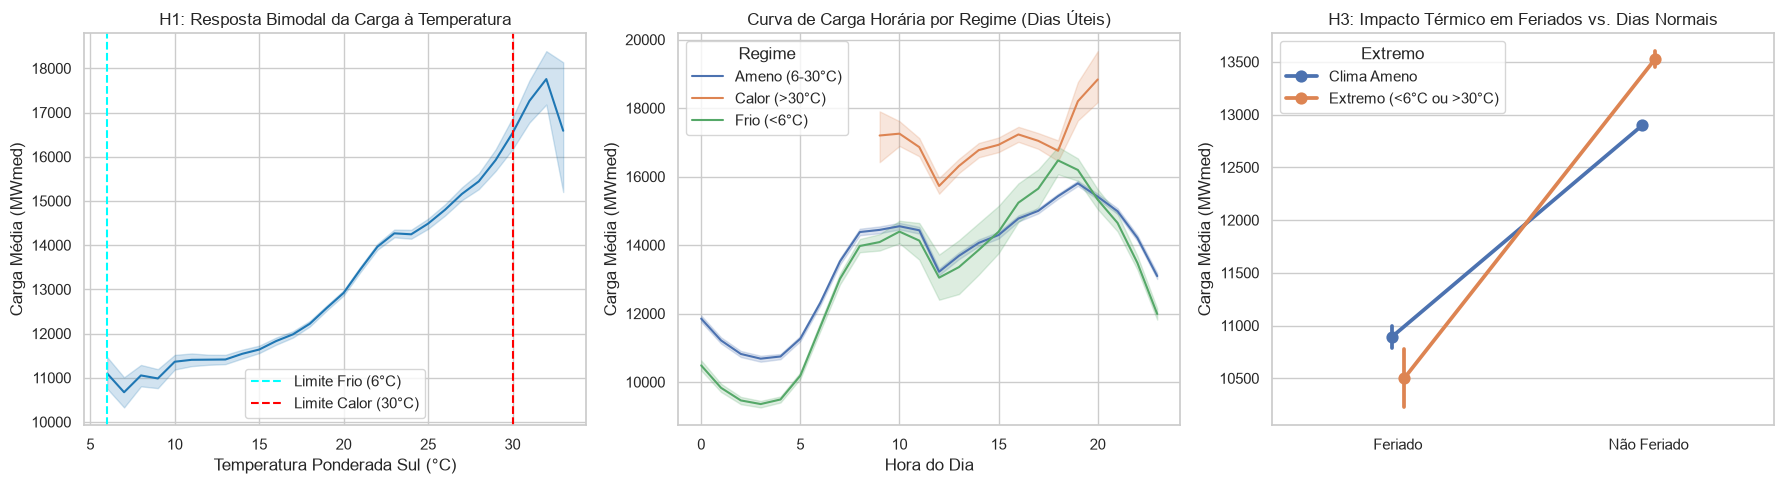

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

df = pd.read_parquet("data/processed/dataset_sul.parquet")
sns.set_theme(style="whitegrid", context="notebook")

def ic_95(serie: pd.Series):
    n = len(serie)
    media = serie.mean()
    erro_padrao = stats.sem(serie)
    margem = erro_padrao * stats.t.ppf(0.975, df=n - 1)
    return media, media - margem, media + margem

# ==============================================================================
# TESTE DA HIPÓTESE 1: Efeito Térmico Bimodal (<6°C e >30°C vs. Ameno)
# ==============================================================================
frio = df.loc[df["extremo_frio"] == 1, "carga_mwmed"]
ameno = df.loc[(df["extremo_frio"] == 0) & (df["extremo_calor"] == 0), "carga_mwmed"]
calor = df.loc[df["extremo_calor"] == 1, "carga_mwmed"]

print("=== HIPÓTESE 1: EFEITO TÉRMICO BIMODAL ===")
for nome, grupo in [("Frio Extremo (<6°C)", frio), ("Clima Ameno (6-30°C)", ameno), ("Calor Extremo (>30°C)", calor)]:
    m, low, high = ic_95(grupo)
    print(f"{nome:22s} | Média: {m:8.2f} MW | IC 95%: [{low:8.2f}, {high:8.2f}] | n={len(grupo)}")

# Teste t de Welch (variâncias desiguais) e Mann-Whitney U
t_frio, p_frio = stats.ttest_ind(frio, ameno, equal_var=False)
t_calor, p_calor = stats.ttest_ind(calor, ameno, equal_var=False)
print(f"Frio vs. Ameno  -> t = {t_frio:.2f}, p-valor = {p_frio:.4e}")
print(f"Calor vs. Ameno -> t = {t_calor:.2f}, p-valor = {p_calor:.4e}\n")

# ==============================================================================
# TESTE DA HIPÓTESE 2: Inércia Térmica (Lags e Acúmulo de Temperatura)
# ==============================================================================
df["temp_lag_24h"] = df["temp_sul_ponderada"].shift(24)
df["temp_media_72h"] = df["temp_sul_ponderada"].rolling(72).mean()
df["cdd_acumulado_72h"] = df["cdd"].rolling(72).sum()
df["hdd_acumulado_72h"] = df["hdd"].rolling(72).sum()

df_valid = df.dropna(subset=["temp_lag_24h", "temp_media_72h"]).copy()

# Correlação parcial / incremental em dias quentes (CDD > 0) e frios (HDD > 0)
r_inst, p_inst = stats.pearsonr(df_valid.loc[df_valid["cdd"] > 0, "cdd"], df_valid.loc[df_valid["cdd"] > 0, "carga_mwmed"])
r_acum, p_acum = stats.pearsonr(df_valid.loc[df_valid["cdd"] > 0, "cdd_acumulado_72h"], df_valid.loc[df_valid["cdd"] > 0, "carga_mwmed"])

print("=== HIPÓTESE 2: INÉRCIA TÉRMICA ===")
print(f"Correlação CDD instantâneo vs. Carga : r = {r_inst:.4f} (p = {p_inst:.4e})")
print(f"Correlação CDD acumulado 72h vs. Carga: r = {r_acum:.4f} (p = {p_acum:.4e})\n")

# ==============================================================================
# TESTE DA HIPÓTESE 3: Interação Feriado x Extremo Térmico em Polos Industriais
# ==============================================================================
df["qualquer_feriado"] = ((df["is_feriado_nacional"] == 1) | (df["is_feriado_estadual_sul"] == 1)).astype(int)
df["qualquer_extremo"] = ((df["extremo_frio"] == 1) | (df["extremo_calor"] == 1)).astype(int)

feriado_ameno = df.loc[(df["qualquer_feriado"] == 1) & (df["qualquer_extremo"] == 0), "carga_mwmed"]
feriado_extremo = df.loc[(df["qualquer_feriado"] == 1) & (df["qualquer_extremo"] == 1), "carga_mwmed"]

m_fa, l_fa, h_fa = ic_95(feriado_ameno)
m_fe, l_fe, h_fe = ic_95(feriado_extremo)
t_h3, p_h3 = stats.ttest_ind(feriado_extremo, feriado_ameno, equal_var=False)

print("=== HIPÓTESE 3: FERIADOS EM EXTREMOS TÉRMICOS ===")
print(f"Feriado + Clima Ameno   | Média: {m_fa:8.2f} MW | IC 95%: [{l_fa:8.2f}, {h_fa:8.2f}] | n={len(feriado_ameno)}")
print(f"Feriado + Extremo Term. | Média: {m_fe:8.2f} MW | IC 95%: [{l_fe:8.2f}, {h_fe:8.2f}] | n={len(feriado_extremo)}")
print(f"Diferença média: +{m_fe - m_fa:.2f} MW (+{(m_fe/m_fa - 1)*100:.2f}%) | t = {t_h3:.2f}, p-valor = {p_h3:.4e}")

# Regressão Linear com Termo de Interação (controlando hora e fim de semana)
modelo_h3 = smf.ols(
    "carga_mwmed ~ qualquer_feriado * qualquer_extremo + C(hora) + is_fim_de_semana",
    data=df
).fit(cov_type="HC3")
print("\nCoeficiente de Interação (qualquer_feriado:qualquer_extremo):")
print(modelo_h3.summary().tables[1])

# ==============================================================================
# GRÁFICOS ANALÍTICOS
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Curva Bimodal (Carga vs Temperatura)
df["faixa_temp"] = df["temp_sul_ponderada"].round()
sns.lineplot(
    data=df[(df["faixa_temp"] >= 6) & (df["faixa_temp"] <= 34)],
    x="faixa_temp", y="carga_mwmed", errorbar=("ci", 95), ax=axes[0], color="#1f77b4"
)
axes[0].axvline(6, color="cyan", linestyle="--", label="Limite Frio (6°C)")
axes[0].axvline(30, color="red", linestyle="--", label="Limite Calor (30°C)")
axes[0].set_title("H1: Resposta Bimodal da Carga à Temperatura")
axes[0].set_xlabel("Temperatura Ponderada Sul (°C)")
axes[0].set_ylabel("Carga Média (MWmed)")
axes[0].legend()

# Gráfico 2: Perfil Horário por Regime Térmico
df["Regime"] = np.where(df["extremo_frio"] == 1, "Frio (<6°C)",
               np.where(df["extremo_calor"] == 1, "Calor (>30°C)", "Ameno (6-30°C)"))
sns.lineplot(
    data=df[df["is_fim_de_semana"] == 0],
    x="hora", y="carga_mwmed", hue="Regime", errorbar=("ci", 95), ax=axes[1]
)
axes[1].set_title("Curva de Carga Horária por Regime (Dias Úteis)")
axes[1].set_xlabel("Hora do Dia")
axes[1].set_ylabel("Carga Média (MWmed)")

# Gráfico 3: Interação Feriado x Extremo Térmico (H3)
df["Tipo_Dia"] = np.where(df["qualquer_feriado"] == 1, "Feriado", "Não Feriado")
df["Extremo"] = np.where(df["qualquer_extremo"] == 1, "Extremo (<6°C ou >30°C)", "Clima Ameno")
sns.pointplot(
    data=df, x="Tipo_Dia", y="carga_mwmed", hue="Extremo",
    errorbar=("ci", 95), dodge=True, ax=axes[2]
)
axes[2].set_title("H3: Impacto Térmico em Feriados vs. Dias Normais")
axes[2].set_xlabel("")
axes[2].set_ylabel("Carga Média (MWmed)")

plt.tight_layout()
plt.savefig("analise_exploratoria_hipoteses.png", dpi=300)
plt.show()